### Goals

- load models trained with different setups
- with each model, predict the test set  
- compute metrics







In [1]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
from pprint import pformat
import pickle

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [2]:
import sys
sys.path.append('../')
from evaluate import compute_and_log_metrics


### Examples of how to filter wandb runs:

example_filters = {


    "group" : "17/5 single-bi-trimodal",
    "config.image_encoder.use": True,
    "config.batch_size": {'$gt': 10}, #Greater than
    "config.batch_size": {'$lte': 10}, #Less than or equal
    
	"$and": [{
		'created_at': {
			"$lt": '2022-03-09T10',
			"$gt": '2022-03-07T17'
		}
	}]
    
}

In [3]:
# Define the filter criteria
'''filter_criteria = {
    'config.image_encoder.use': True,
    #'config.tabular_encoder.use': True,
    #'config.loc_encoder.use': True,
    
    "group" : "25/5 eval freezing enc, modalities, n of examples",
    "config.seed" : 420,
    "$or": [{
        'config.train_examples_per_class': {
            "$gt": '200',
        }
    },
        {
        'config.train_examples_per_class': {
            "$lt": '200',
        }
    }
    ]
}'''


'filter_criteria = {\n    \'config.image_encoder.use\': True,\n    #\'config.tabular_encoder.use\': True,\n    #\'config.loc_encoder.use\': True,\n    \n    "group" : "25/5 eval freezing enc, modalities, n of examples",\n    "config.seed" : 420,\n    "$or": [{\n        \'config.train_examples_per_class\': {\n            "$gt": \'200\',\n        }\n    },\n        {\n        \'config.train_examples_per_class\': {\n            "$lt": \'200\',\n        }\n    }\n    ]\n}'

In [4]:
group_names = [
    '13/9 n images',
]

In [5]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
assert device == 'cuda'
n_classes = 11
CHECKPOINT_TYPE = 'last'


In [6]:
all_models = []

In [7]:
for group_name in group_names:
    
    filter_criteria = {
        "group" : group_name,
        }
    models = utils.get_wandb_runs(filter_criteria)
    print(f'models in group {group_name}: {len(models)}')
    
    
    for i, model_dict in enumerate(tqdm.tqdm(models)):
        model_dict['summary'] = None
        try:
            metrics, preds = utils.load_model_and_predict(model_dict, n_classes, device, 'val', CHECKPOINT_TYPE)
        except Exception as e:
            print(e)
            continue
        model_dict['predictions'] = preds
        model_dict['metrics'] = metrics
    all_models.extend(models)


models in group 13/9 n images: 150


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 150/150 [16:56<00:00,  6.78s/it]


In [8]:
len(all_models)

150

In [3]:

filename = '13_9_n_images'

In [10]:
#with open(f'{filename}.pickle', 'wb') as handle:
#    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [4]:


with open(f'{filename}.pickle', 'rb') as handle:
    loaded_models = pickle.load(handle)


In [12]:
#models = [model for model in other_models  if model['config']['two_model_regularization']['use'] == False]
#models = [model for model in models  if model['config']['model_version'] == 'v1']




In [7]:
models_ = [model for model in loaded_models if model['config'] != {}]
models__ = [model for model in models_ if 'metrics' in model.keys()]


In [8]:
print(len(models__))

150


In [9]:
models = models__

In [10]:
import importlib
importlib.reload(utils)


<module 'utils' from '/home/jan/Documents/EPFL/project_2/notebooks/../utils.py'>

In [11]:
hyperparams_values = utils.find_keys_with_multiple_values([model['config'] for model in models])

In [12]:
hyperparams_values

{'seed': [420, 422, 423, 424, 425],
 'n_images': [1, 2, 3, 4, 6],
 'train_dataset_total_size': [1000, 5000, 200, 10000, 2000, 500]}

In [13]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_no_regrowth.csv")
labels = labels.loc[labels['split'] == 4].reset_index(drop=True) # Get test examples 

targets = labels['driver'].map(LABEL_MAPPING).to_numpy()


In [14]:
def get_models_with_config(_models, target_config):
    
    def has_key_value_pair(d, target):
        if isinstance(d, dict) and isinstance(target, dict):
            for key, value in target.items():
                if key in d:
                    if isinstance(value, dict) and isinstance(d[key], dict):
                        if not has_key_value_pair(d[key], value):
                            return False
                    else:
                        if d[key] != value:
                            return False
                else:
                    return False
            return True
        return d == target
    
    models_with_this_config_combination = []
    for model in _models:
        skip_model = False
        for key in target_config.keys():
            if not has_key_value_pair(model['config'][key],target_config[key]):
            #if model['config'][key] != target_config[key]:
                skip_model = True
                break
        if skip_model:
            continue
        models_with_this_config_combination.append(model)
    
    return models_with_this_config_combination

In [15]:
exclude_keys = ['seed']

combinations = utils.generate_combinations(hyperparams_values, exclude_keys)

In [16]:
#This I need to do in case there is only 1 seed
#hyperparams_values['seed'] = [420]

In [17]:

performance_per_configuration = {}

for combo in combinations:
    
    metrics_per_random_seed = []
    combo_str = ' '.join(pformat(combo, width=1).split())
    #print(combo_str)

    #Compute metrics per each random seed separately
    for seed in hyperparams_values['seed']:
        combo['seed'] = seed 
        
        #Get all models that have the configuration setup 
        model_with_this_config = get_models_with_config(models, combo)
        if not model_with_this_config:
            continue

            
        assert len(model_with_this_config) == 1, f"there should be 1 model with a config, found {len(model_with_this_config)}"
        model_with_this_config = model_with_this_config[0]
        if not 'metrics' in model_with_this_config.keys():
            continue
            
            
        metrics_per_random_seed.append(pd.DataFrame(model_with_this_config['metrics']))


    if not metrics_per_random_seed:
        print("no metrics for: ", combo)
        continue


    # Concatenate DataFrames along a new axis
    concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

    # Compute the mean along the new axis
    mean_df = concat_df.groupby(level=1).mean()

    # Compute the standard deviation along the new axis
    std_df = concat_df.groupby(level=1).std()   
    
    

    performance_per_configuration[combo_str] = {}
    performance_per_configuration[combo_str]['mean'] = mean_df
    performance_per_configuration[combo_str]['std'] = std_df



        

In [18]:
#performance_per_configuration = {key:value for key, value in performance_per_configuration.items() if "{'model_version': 'v2', 'tabular_encoder': {'use': False}" not in key}


In [19]:
#models_100_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 100}" in key}
models_200_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 200}" in key}
models_500_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 500}" in key}
models_1000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 1000}" in key}
models_2000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 2000}" in key}
models_5000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 5000}" in key}
models_10000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 10000}" in key}
#models_20000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 20000}" in key}


In [20]:
def plot_metrics(metrics, metric='accuracy', ylim=(0.2, 1.2) ):
    
    class_names = list(LABEL_MAPPING.keys())
    class_names.append(metric)
    stats = {}
    for model_name, model_stats in metrics.items():
        stats[model_name] = {}
        for cls in class_names:
            stats[model_name][cls] = {}
            stats[model_name][cls]['score'] = metrics[model_name]['mean'][cls]['f1-score']
            stats[model_name][cls]['std'] = metrics[model_name]['std'][cls]['f1-score']

    # Initialize plot
    fig, ax = plt.subplots(figsize=(12, 6))

    # Set the width of the bars
    bar_width = 0.7/len(metrics)

    # Set positions of the bars on the x-axis
    index = np.arange(len(class_names))

    # Plot each model's data

    #for i, model in enumerate(stats.keys()):
    for i, model in enumerate(list(metrics.keys())): #only models with image
        scores = [stats[model][cls]['score'] for cls in class_names]
        stds = [stats[model][cls]['std'] for cls in class_names]
        ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

    # Set labels, title, and legend
    #ax.set_xlabel('Class')
    #ax.set_ylabel('Score')
    plt.ylim(bottom=ylim[0])
    plt.ylim(top=ylim[1])
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.legend()

    # Show plot
    plt.tight_layout()
    plt.show()

In [56]:
models_10000_dst["{'n_images': 1, 'train_dataset_total_size': 10000}"]['mean']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg,loss
f1-score,0.812192,0.593214,0.773385,0.561086,0.799126,0.794633,0.880707,0.957320,0.878815,0.980984,0.825019,0.841009,0.805135,0.840613,0.520525
precision,0.777526,0.567616,0.739554,0.569691,0.836167,0.899064,0.841543,0.936897,0.890360,0.971446,0.886064,0.841009,0.810539,0.847692,0.520525
recall,0.852607,0.633493,0.814966,0.561616,0.772596,0.712782,0.926641,0.978796,0.870330,0.990747,0.773427,0.841009,0.808000,0.841009,0.520525
support,422.000000,209.000000,441.000000,198.000000,416.000000,532.000000,259.000000,1113.000000,455.000000,281.000000,429.000000,0.841009,4755.000000,4755.000000,0.520525


In [59]:
models_10000_dst["{'n_images': 3, 'train_dataset_total_size': 10000}"]['mean']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg,loss
f1-score,0.851346,0.663124,0.821223,0.633147,0.806075,0.843259,0.935232,0.962065,0.864258,0.972414,0.865504,0.866919,0.837968,0.866480,0.450751
precision,0.829723,0.612157,0.792160,0.695645,0.810883,0.928786,0.926019,0.938258,0.891729,0.967967,0.909130,0.866919,0.845678,0.872445,0.450751
recall,0.876777,0.735885,0.854875,0.583838,0.811538,0.773684,0.945946,0.987242,0.842637,0.977936,0.826573,0.866919,0.837903,0.866919,0.450751
support,422.000000,209.000000,441.000000,198.000000,416.000000,532.000000,259.000000,1113.000000,455.000000,281.000000,429.000000,0.866919,4755.000000,4755.000000,0.450751


In [57]:
models_10000_dst["{'n_images': 4, 'train_dataset_total_size': 10000}"]['mean']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg,loss
f1-score,0.856523,0.672625,0.853830,0.619984,0.813426,0.842621,0.932652,0.960755,0.861195,0.986247,0.860393,0.871462,0.841841,0.870021,0.4561
precision,0.828414,0.648199,0.810457,0.696500,0.827117,0.931609,0.944872,0.931387,0.889876,0.979039,0.892442,0.871462,0.852719,0.875772,0.4561
recall,0.890521,0.714833,0.902494,0.574747,0.804808,0.770301,0.922780,0.992093,0.840879,0.993594,0.832634,0.871462,0.839971,0.871462,0.4561
support,422.000000,209.000000,441.000000,198.000000,416.000000,532.000000,259.000000,1113.000000,455.000000,281.000000,429.000000,0.871462,4755.000000,4755.000000,0.4561


In [58]:
models_10000_dst["{'n_images': 6, 'train_dataset_total_size': 10000}"]['mean']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg,loss
f1-score,0.868838,0.668408,0.883599,0.607182,0.810520,0.849247,0.942287,0.959946,0.869484,0.974478,0.878420,0.87613,0.846582,0.875703,0.442469
precision,0.851173,0.634999,0.843019,0.648404,0.817029,0.938158,0.944919,0.933803,0.898543,0.986854,0.912476,0.87613,0.855398,0.881746,0.442469
recall,0.890521,0.731100,0.930612,0.580808,0.810577,0.777068,0.941313,0.987781,0.843077,0.963701,0.848019,0.87613,0.845871,0.876130,0.442469
support,422.000000,209.000000,441.000000,198.000000,416.000000,532.000000,259.000000,1113.000000,455.000000,281.000000,429.000000,0.87613,4755.000000,4755.000000,0.442469


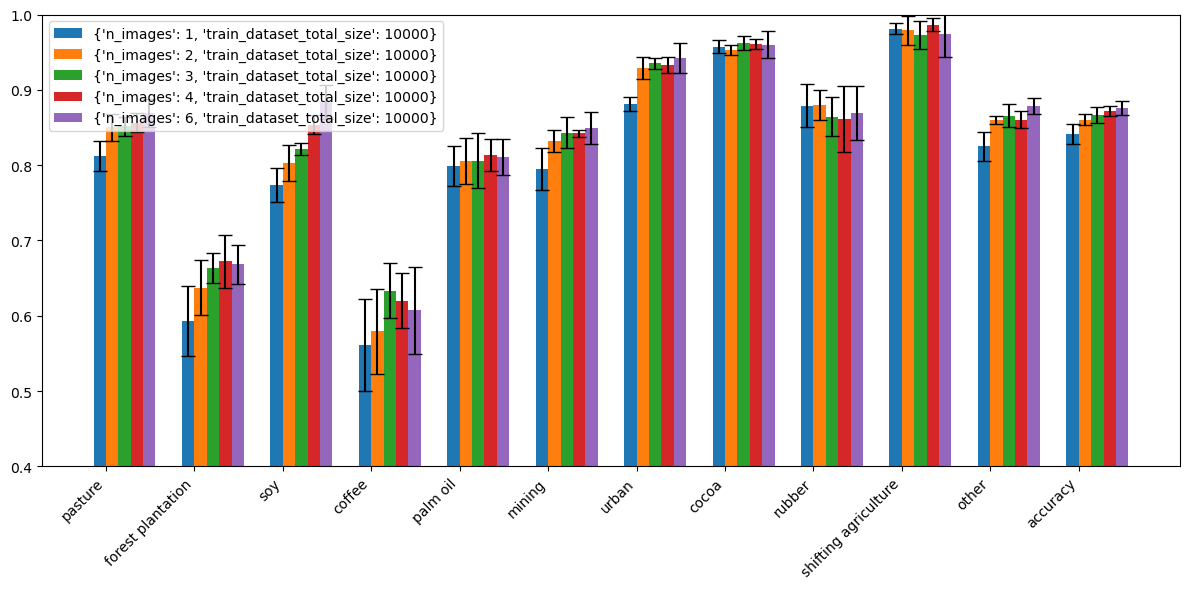

In [21]:
plot_metrics(models_10000_dst, ylim=(0.4, 1))

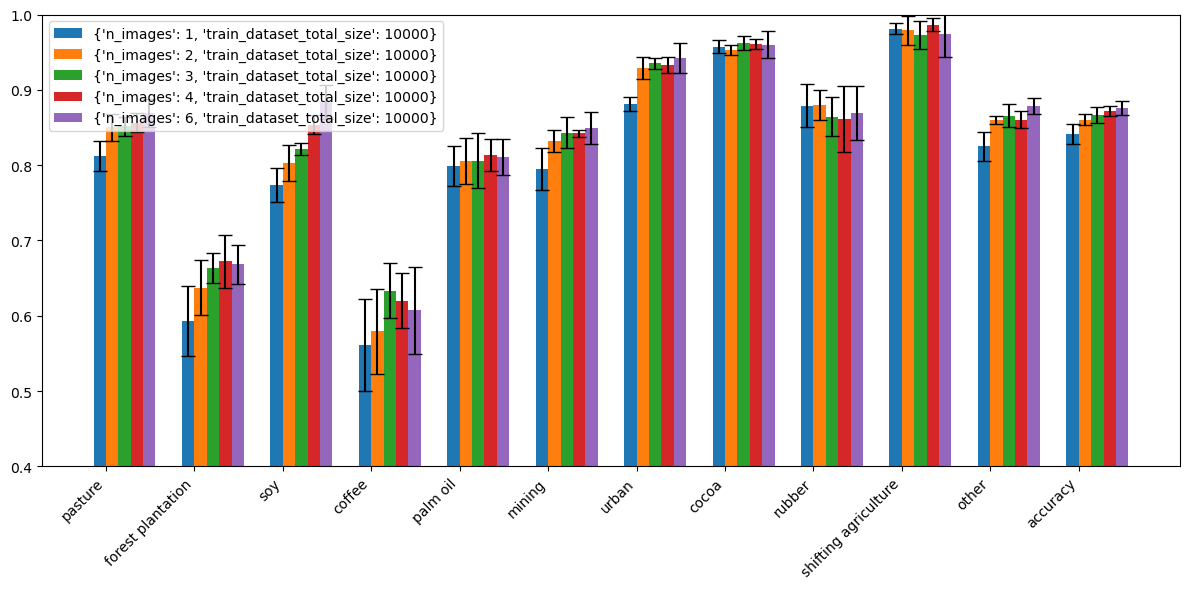

In [40]:
plot_metrics(models_10000_dst, ylim=(0.4, 1))

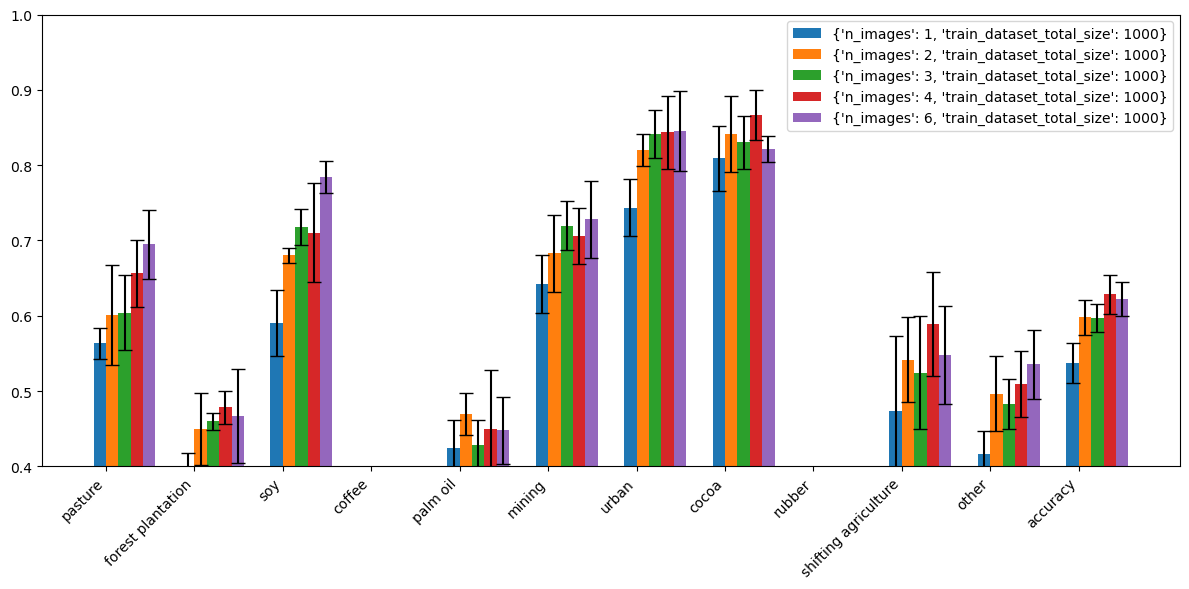

In [90]:
plot_metrics(models_1000_dst, ylim=(0.4, 1))

In [ ]:
# plot_metrics(models_20000_dst, ylim=(0.4, 1))

In [66]:
performance_per_configuration["{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 500}"]['mean']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg,loss
f1-score,0.725625,0.438589,0.716233,0.374233,0.388325,0.690914,0.707506,0.919180,0.449014,0.912813,0.647592,0.69367,0.633639,0.685984,1.319481
precision,0.692040,0.361854,0.698139,0.365416,0.435837,0.730283,0.809687,0.863323,0.626526,0.910335,0.666880,0.69367,0.650938,0.697218,1.319481
recall,0.776303,0.577033,0.737868,0.389899,0.351923,0.657895,0.631660,0.982929,0.358242,0.920996,0.633566,0.69367,0.638029,0.693670,1.319481
support,422.000000,209.000000,441.000000,198.000000,416.000000,532.000000,259.000000,1113.000000,455.000000,281.000000,429.000000,0.69367,4755.000000,4755.000000,1.319481


In [22]:
import ast
import re


# Function to remove 'seed' key-value pairs from a string representation of a dictionary
def remove_seed(entry):
    # Remove the seed key-value pair using regular expressions
    cleaned_entry = re.sub(r"'seed': \d+,? ?", "", entry)
    return cleaned_entry

In [23]:
performance_per_configuration_renamed = {}

for key, value in performance_per_configuration.items():
    performance_per_configuration_renamed[remove_seed(key)] = value
    

In [24]:
performance_per_configuration_renamed

{"{'n_images': 1, 'train_dataset_total_size': 1000}": {'mean':               pasture  forest plantation         soy      coffee    palm oil  \
  f1-score     0.712113           0.471520    0.601326    0.412710    0.544128   
  precision    0.653313           0.454000    0.606471    0.381210    0.614372   
  recall       0.796682           0.495694    0.609524    0.452525    0.504808   
  support    422.000000         209.000000  441.000000  198.000000  416.000000   
  
                 mining       urban        cocoa      rubber  \
  f1-score     0.543453    0.740839     0.897611    0.620505   
  precision    0.731652    0.732790     0.835540    0.757448   
  recall       0.446617    0.762934     0.971069    0.556923   
  support    532.000000  259.000000  1113.000000  455.000000   
  
             shifting agriculture       other  accuracy    macro avg  \
  f1-score               0.897305    0.600722  0.692282     0.640203   
  precision              0.889652    0.606844  0.692282    

In [93]:
#list(set(performance_per_configuration_renamed.keys()))

In [25]:
def process_stats_all(___models, metric='accuracy', n_examples_list=[200, 500, 1000, 2000, 5000, 10000, 20000]):


    _models_stats = {}

    _models_stats["{'n_images': 1, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'n_images': 2, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'n_images': 3, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'n_images': 4, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'n_images': 6, xx}"] = {'acc' : [], 'std': []}

    
    for n_examples in n_examples_list:

        #for key in _models.keys():
        selected_models = {key:value for key, value in ___models.items() if f"'train_dataset_total_size': {n_examples}}}" in key}
        for key in _models_stats.keys():
            model_name = key.replace("xx", f"'train_dataset_total_size': {n_examples}") 
            sel_model = selected_models[model_name]
            acc = sel_model['mean'][metric]['f1-score']
            std = sel_model['std'][metric]['f1-score']
            _models_stats[key]['acc'].append(acc)
            _models_stats[key]['std'].append(std)


        
    return _models_stats
    

In [104]:
#_models_stats_reg = process_stats_reg(reg_models)
#_models_stats_all = process_stats_all(performance_per_configuration_renamed)
#_models_f1 = process_stats_all(performance_per_configuration_renamed, 'macro avg')



In [26]:


run_names = {
    "{'n_images': 1, xx}" : "1 image",
    "{'n_images': 2, xx}" : "2 images",
    "{'n_images': 3, xx}" : "3 images",
    "{'n_images': 4, xx}" : "4 images",
    "{'n_images': 6, xx}" : "6 images",

}

In [30]:

def _plot_dict(_dict, x_axis_vals, names):
    
    for key, value in _dict.items():
        name = names[key] if names is not None else key
        acc = value['acc']
        std = value['std']
        plt.errorbar(x_axis_vals, acc, yerr=std, label=name, capsize=5)

    plt.xlabel('Training dataset size')
    plt.ylabel('Accuracy')
    plt.title('N of input images ')
    plt.legend()
    plt.ylim(bottom=0.45)
    plt.ylim(top=0.9)
    #plt.xscale('log')
    plt.grid(True)
    plt.show()

In [28]:
def plot_metric(_model_stats, metric, run_names=None, n_examples=[200, 500, 1000, 2000, 5000, 10000, 20000]):
    processed_stats = process_stats_all(_model_stats, metric, n_examples_list=n_examples)
    _plot_dict(processed_stats, n_examples, run_names)

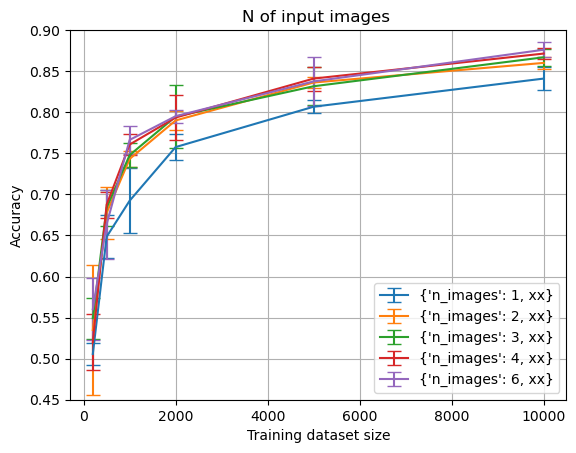

In [31]:
plot_metric(performance_per_configuration_renamed, 'accuracy', n_examples=[200, 500, 1000, 2000, 5000, 10000])

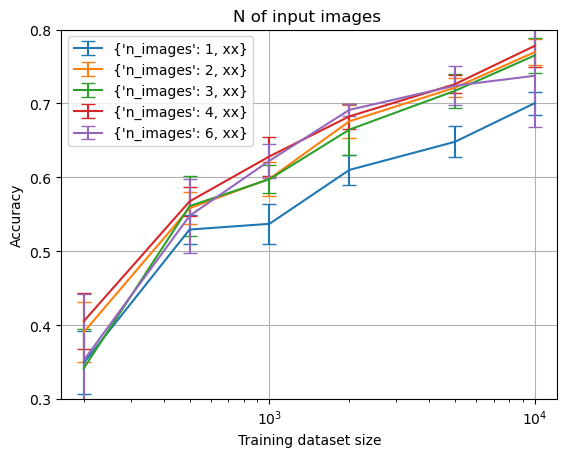

In [148]:
plot_metric(performance_per_configuration_renamed, 'accuracy', n_examples=[200, 500, 1000, 2000, 5000, 10000])